<a href="https://colab.research.google.com/github/quarcs-lab/geo4cambodia/blob/main/notebooks/hdi_ntl_esda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **A geocomputational notebook to monitor the dynamics of regional development**

Carlos Mendez (Nagoya Univerisity)


[![DOI](https://zenodo.org/badge/683583423.svg)](https://zenodo.org/badge/latestdoi/683583423)
```
Suggested citation:
Mendez, C.(2023). A geocomputational notebook to monitor the dynamics of regional development. Zenodo. https://doi.org/10.5281/zenodo.828685
```

## 0) Motivation

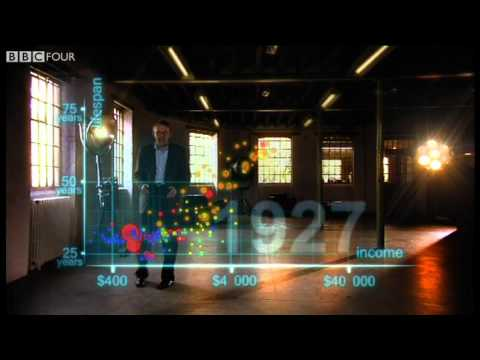

In [1]:
# @title Development differences across and within coutries

from IPython.display import YouTubeVideo

YouTubeVideo(id='jbkSRLYSojo', width=600, height=400, autoplay=False, controls=True)

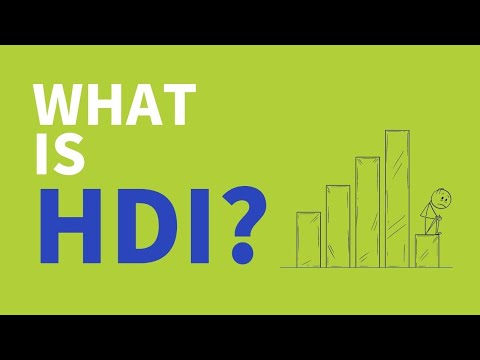

In [2]:
# @title The human development index

from IPython.display import YouTubeVideo

YouTubeVideo(id='1ScfqaCp2Ho', width=600, height=400, autoplay=False, controls=True)

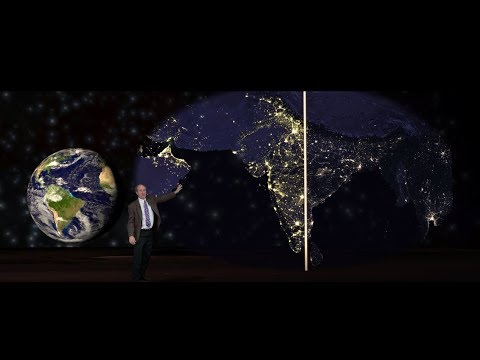

In [3]:
# @title Studying economic development from outer space

from IPython.display import YouTubeVideo

YouTubeVideo(id='rm1gCLfaZnE', width=600, height=400, autoplay=False, controls=True)

This compuational notebook uses  estimates from the subnational human development database of
>  [Smits, J., & Permanyer, I. (2019). The subnational human development database. Scientific data, 6(1), 1-15.](https://www.nature.com/articles/sdata201938)

An overview of the dataset can be found here:
- [Short note introducing the dataset](https://hdr.undp.org/en/content/subnational-human-development-index-moving-beyond-country-level-averages)
- [Paper introducing the dataset](https://www.nature.com/articles/sdata201938)

This notebook is based on version 5.0 of the database, which is mantained and distributed by the Global Data Lab of the Radboud University of The Netherlands. The database can be freely downloaded from https://globaldatalab.org/shdi/download_files/.

The notebook also uses satellite nighttime light images from from
> [Li, X., Zhou, Y., Zhao, M. et al. A harmonized global nighttime light dataset 1992–2018. Sci Data 7, 168 (2020)](https://doi.org/10.1038/s41597-020-0510-y)

The repository of images is available at https://doi.org/10.6084/m9.figshare.9828827.v8

## 1) Setup

In [4]:
# Install only what this environment lacks (Colab lacks the spatial libraries; a local `uv sync` has them all)
import importlib.util

missing = [p for p in ("contextily", "splot", "rasterio", "mapclassify", "inequality", "mgwr") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [5]:
#!pip install linearmodels==4.27 -q  # Library for linear models and instrumental variables

In [6]:
# Importing necessary libraries for data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable  # Function to create a new axis on a plot

import seaborn as sns
sns.set(style="darkgrid", context="paper", font_scale=1.02)  # Setting seaborn styles

import glob
import os
import requests
import zipfile
from io import BytesIO

import plotly.express as px
import plotly.graph_objects as go

# Importing libraries for spatial data and visualization
import geopandas as gpd
import contextily as cx

import libpysal
from libpysal import weights
from libpysal.weights import Queen

import rasterio  # Library for raster data processing
from rasterio import plot as rioplot  # Function to plot raster data
from rasterio.mask import mask  # Function for masking raster data using shapefile for zonal statistics

# Exploratory Spatial Data Analysis (ESDA) tools
import mapclassify as mc
import esda
from esda.moran import Moran, Moran_Local

# Spatial plotting tools
import splot
from splot.esda import moran_scatterplot, plot_moran, lisa_cluster, plot_local_autocorrelation
from splot.libpysal import plot_spatial_weights
from splot.mapping import vba_choropleth

# Library for inequality analysis
import inequality
from inequality.gini import Gini_Spatial

# Statistical modeling
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Geographically Weighted Regression (GWR) and related utilities
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW
from mgwr.utils import shift_colormap, truncate_colormap

# linearmodels library provides helps performing regressions
#from linearmodels import PooledOLS  # Function to perform pooled OLS regression
#from linearmodels import PanelOLS  # Function to perform OLS regression on panel data
#from linearmodels import BetweenOLS  # Function to compute the between estimator of an OLS regression
#from linearmodels.panel.results import compare  # Function to compare results of an OLS regression

# Suppressing warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

## 2) Import data and set key variables

### 2.1) Import dataframe

In [7]:
df = pd.read_csv("https://github.com/quarcs-lab/data-open/raw/master/shdi/SHDIold.csv").sort_values(by=['year', 'SubContinent'])
df["year"]= df["year"].astype(str)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54668 entries, 2087 to 45190
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   iso_code         54668 non-null  object 
 1   country          54668 non-null  object 
 2   year             54668 non-null  object 
 3   GDLcode          54668 non-null  object 
 4   continent2       54668 non-null  object 
 5   level            54668 non-null  object 
 6   region           54668 non-null  object 
 7   continent        54668 non-null  object 
 8   CountryName_std  54668 non-null  object 
 9   shdi             54668 non-null  float64
 10  healthindex      54668 non-null  float64
 11  incindex         54668 non-null  float64
 12  edindex          54668 non-null  float64
 13  esch             54668 non-null  float64
 14  msch             54668 non-null  float64
 15  lifexp           54668 non-null  float64
 16  gnic             54668 non-null  float64
 17  lgnic         

In [9]:
df

,iso_code,country,year,GDLcode,continent2,level,region,continent,CountryName_std,shdi,...,lgnic,pop,POLY_IDcountry,iso3,status,CountryName,SubContinent,Continent,Continent_std,_merge
2087,AUS,Australia,1990,AUSr105,Oceania,Subnat,Western Australia,Asia/Pacific,Australia,0.874,...,10.334,1566.240,14.0,AUS,Member State,Australia,Australia and New Zealand,Oceania,Oceania,Matched (3)
2106,AUS,Australia,1990,AUSr101,Oceania,Subnat,New South Wales,Asia/Pacific,Australia,0.874,...,10.386,5833.478,14.0,AUS,Member State,Australia,Australia and New Zealand,Oceania,Oceania,Matched (3)
2165,AUS,Australia,1990,AUSt,Oceania,National,Total,Asia/Pacific,Australia,0.871,...,10.319,17065.100,14.0,AUS,Member State,Australia,Australia and New Zealand,Oceania,Oceania,Matched (3)
2171,AUS,Australia,1990,AUSr107,Oceania,Subnat,Northern Territory,Asia/Pacific,Australia,0.831,...,10.418,167.852,14.0,AUS,Member State,Australia,Australia and New Zealand,Oceania,Oceania,Matched (3)
2198,AUS,Australia,1990,AUSr106,Oceania,Subnat,Tasmania,Asia/Pacific,Australia,0.840,...,10.069,456.316,14.0,AUS,Member State,Australia,Australia and New Zealand,Oceania,Oceania,Matched (3)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45115,CHE,Switzerland,2019,CHEr103,Europe,Subnat,Northwestern Switzerland,Europe,Switzerland,0.950,...,11.182,1165.223,148.0,CHE,Member State,Switzerland,Western Europe,Europe,Europe,Matched (3)
45156,CHE,Switzerland,2019,CHEr107,Europe,Subnat,Ticino,Europe,Switzerland,0.954,...,11.188,354.596,148.0,CHE,Member State,Switzerland,Western Europe,Europe,Europe,Matched (3)
45167,CHE,Switzerland,2019,CHEr104,Europe,Subnat,Zurich,Europe,Switzerland,0.980,...,11.350,1526.362,148.0,CHE,Member State,Switzerland,Western Europe,Europe,Europe,Matched (3)
45183,CHE,Switzerland,2019,CHEt,Europe,National,Total,Europe,Switzerland,0.956,...,11.148,8574.832,148.0,CHE,Member State,Switzerland,Western Europe,Europe,Europe,Matched (3)


### 2.2) Import map

In [10]:
map = gpd.read_file("https://gist.github.com/cmg777/81b6e2b1ea5865c09daf3b2bbf35bbf8/raw/5e0a0370f453421bc503594cfae1e466c89e449f/GDL%2520Shapefiles%2520V4.geojson")

In [11]:
map.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1745 entries, 0 to 1744
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   GDLcode   1745 non-null   object  
 1   constant  1745 non-null   object  
 2   iso_code  1742 non-null   object  
 3   country   1742 non-null   object  
 4   region    1742 non-null   object  
 5   shdi      1742 non-null   float64 
 6   geometry  1745 non-null   geometry
dtypes: float64(1), geometry(1), object(5)
memory usage: 95.6+ KB


In [12]:
map

,GDLcode,constant,iso_code,country,region,shdi,geometry
0,AFGr101,World,AFG,Afghanistan,Central (Kabul Wardak Kapisa Logar Parwan Panj...,0.573915,"MULTIPOLYGON (((67.61506 34.23957, 67.59259 34..."
1,AFGr102,World,AFG,Afghanistan,Central Highlands (Bamyan Daikundi),0.484076,"MULTIPOLYGON (((65.23611 33.37125, 65.25839 33..."
2,AFGr103,World,AFG,Afghanistan,East (Nangarhar Kunar Laghman Nooristan),0.477673,"MULTIPOLYGON (((69.92137 34.02534, 69.90879 34..."
3,AFGr104,World,AFG,Afghanistan,North (Samangan Sar-e-Pul Balkh Jawzjan Faryab),0.514833,"MULTIPOLYGON (((66.38873 34.93133, 66.3311 34...."
4,AFGr105,World,AFG,Afghanistan,North East (Baghlan Takhar Badakhshan Kunduz),0.460395,"MULTIPOLYGON (((67.39591 35.4384, 67.45535 35...."
...,...,...,...,...,...,...,...
1740,ZWEr106,World,ZWE,Zimbabwe,Matebeleland South,0.536536,"MULTIPOLYGON (((29.36831 -22.19781, 29.33401 -..."
1741,ZWEr107,World,ZWE,Zimbabwe,Midlands,0.560737,"MULTIPOLYGON (((29.2265 -19.48012, 29.21404 -1..."
1742,ZWEr108,World,ZWE,Zimbabwe,Masvingo,0.558965,"MULTIPOLYGON (((31.06733 -22.34189, 31.08549 -..."
1743,ZWEr109,World,ZWE,Zimbabwe,Harare,0.645073,"MULTIPOLYGON (((31.08852 -17.66625, 31.11562 -..."


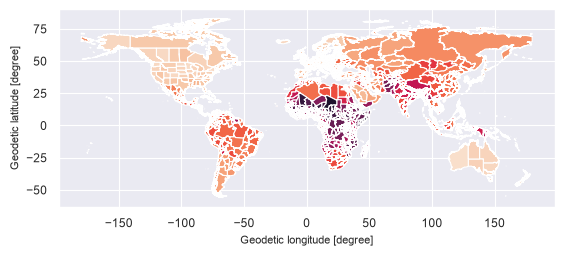

In [13]:
map.plot('shdi');

### 2.1) Prepare dictionary

In [14]:
# Prepare dictionary of variables and labels
column_names = ['Variable', 'Label']
data = [
    ['iso_code', 'ISO Code'],
    ['country', 'Country'],
    ['year', 'Year'],
    ['GDLcode', 'GDL Code'],
    ['continent2', 'Continent 2'],
    ['level', 'Level'],
    ['region', 'Region'],
    ['continent', 'Continent'],
    ['CountryName_std', 'Country Name (Standardized)'],
    ['shdi', 'Human Development Index'],
    ['healthindex', 'Health Index'],
    ['incindex', 'Income Index'],
    ['edindex', 'Education Index'],
    ['esch', 'Expected Schooling (Years)'],
    ['msch', 'Mean Schooling (Years)'],
    ['lifexp', 'Life Expectancy'],
    ['gnic', 'Gross National Income per Capita'],
    ['lgnic', 'Logged Gross National Income per Capita'],
    ['pop', 'Population'],
    ['POLY_IDcountry', 'POLY ID (Country)'],
    ['iso3', 'ISO3'],
    ['status', 'Status'],
    ['CountryName', 'Country Name'],
    ['SubContinent', 'Subcontinent'],
    ['Continent', 'Continent'],
    ['Continent_std', 'Continent (Standardized)'],
    ['_merge', 'Merge']
]

dataDefinitions  = pd.DataFrame(data, columns=column_names)

In [15]:
dataDefinitions

,Variable,Label
0,iso_code,ISO Code
1,country,Country
2,year,Year
3,GDLcode,GDL Code
4,continent2,Continent 2
5,level,Level
6,region,Region
7,continent,Continent
8,CountryName_std,Country Name (Standardized)
9,shdi,Human Development Index


In [16]:
data_dict = dict(zip(dataDefinitions['Variable'], dataDefinitions['Label']))

### 2.2) Set key variables

In [17]:
COUNTRY = 'Cambodia'
#COUNTRY = 'Indonesia'
#COUNTRY = 'Lao'
#COUNTRY = 'India'
#COUNTRY = 'Bolivia'
#COUNTRY = 'Thailand'

In [18]:
FOCUS_YEAR = '2019'

In [19]:
INDICATOR1 = 'shdi'

In [20]:
INDICATOR2 = 'healthindex'

In [21]:
INDICATOR3 = 'incindex'

In [22]:
INDICATOR4 = 'edindex'

In [23]:
INDICATOR5 = 'pop'

In [24]:
INDICATOR6 = 'lgnic'

In [25]:
INDICATOR7 = 'gnic'

In [26]:
ADM1 = 'region'

In [27]:
ADM2 = 'region'

In [28]:
ADM3 = 'region'

In [29]:
startYear = 2013

In [30]:
endYear   = 2019

In [31]:
years = np.arange(startYear, endYear+1).astype(str)

## 3) Data processing, selection, and fitering

In [32]:
# Remove national observations and focus on Cambodia
df1 = df[(df.level != 'National') & (df.country == COUNTRY)]

In [33]:
# Save df1 as csv
df1.to_csv("df1.csv", index = False)

In [34]:
mapCountry = map[map['country'] == COUNTRY][['GDLcode', 'geometry']]

In [35]:
gdf = mapCountry.merge(df1[df1['year'] == FOCUS_YEAR], on=['GDLcode'], how='left')
# Save gdf as geojson file
gdf.to_file("gdf_full.geojson", driver="GeoJSON")

In [36]:
# Drop unnecessary columsn
columns_to_drop = ['iso_code', 'country', 'year', 'continent2', 'level', 'continent', 'CountryName_std', 'shdi', 'healthindex', 'incindex', 'edindex', 'esch', 'msch', 'lifexp', 'gnic', 'lgnic', 'pop', 'POLY_IDcountry', 'iso3', 'status', 'CountryName', 'SubContinent','Continent', 'Continent_std', '_merge']
gdf = gdf.drop(columns=columns_to_drop)
# Save gdf as geojson file
gdf.to_file("gdf.geojson", driver="GeoJSON")

In [37]:
# Select key variable
df1_INDICATOR1 = df1.loc[df1['country'] == COUNTRY, ['GDLcode', ADM3, 'year', INDICATOR1]]
# Pivot panel data from long form to wide form
df1_wide_INDICATOR1 = df1_INDICATOR1.pivot_table(
    index=["GDLcode", ADM3],
    columns="year",
    values= INDICATOR1).reset_index(drop=False)
# Make sure the column names are strings
df1_wide_INDICATOR1.columns = df1_wide_INDICATOR1.columns.astype(str)
# Merge with polygonsFile
gdf_INDICATOR1 = mapCountry.merge(df1_wide_INDICATOR1, on=['GDLcode'], how='left')
# Save gdf_INDICATOR1 as geojson file
gdf_INDICATOR1.to_file("gdf_INDICATOR1.geojson", driver="GeoJSON")

In [38]:
# Select key variable
df1_INDICATOR2 = df1.loc[df1['country'] == COUNTRY, ['GDLcode', ADM3, 'year', INDICATOR2]]
# Pivot panel data from long form to wide form
df1_wide_INDICATOR2 = df1_INDICATOR2.pivot_table(
    index=["GDLcode", ADM3],
    columns="year",
    values= INDICATOR2).reset_index(drop=False)
# Make sure the column names are strings
df1_wide_INDICATOR2.columns = df1_wide_INDICATOR2.columns.astype(str)
# Merge with polygonsFile
gdf_INDICATOR2 = mapCountry.merge(df1_wide_INDICATOR2, on=['GDLcode'], how='left')
# Save gdf_INDICATOR2 as geojson file
gdf_INDICATOR2.to_file("gdf_INDICATOR2.geojson", driver="GeoJSON")

In [39]:
# Select key variable
df1_INDICATOR3 = df1.loc[df1['country'] == COUNTRY, ['GDLcode', ADM3, 'year', INDICATOR3]]
# Pivot panel data from long form to wide form
df1_wide_INDICATOR3 = df1_INDICATOR3.pivot_table(
    index=["GDLcode", ADM3],
    columns="year",
    values= INDICATOR3).reset_index(drop=False)
# Make sure the column names are strings
df1_wide_INDICATOR3.columns = df1_wide_INDICATOR3.columns.astype(str)
# Merge with polygonsFile
gdf_INDICATOR3 = mapCountry.merge(df1_wide_INDICATOR3, on=['GDLcode'], how='left')
# Save gdf_INDICATOR3 as geojson file
gdf_INDICATOR3.to_file("gdf_INDICATOR3.geojson", driver="GeoJSON")

In [40]:
# Select key variable
df1_INDICATOR4 = df1.loc[df1['country'] == COUNTRY, ['GDLcode', ADM3, 'year', INDICATOR4]]
# Pivot panel data from long form to wide form
df1_wide_INDICATOR4 = df1_INDICATOR4.pivot_table(
    index=["GDLcode", ADM3],
    columns="year",
    values= INDICATOR4).reset_index(drop=False)
# Make sure the column names are strings
df1_wide_INDICATOR4.columns = df1_wide_INDICATOR4.columns.astype(str)
# Merge with polygonsFile
gdf_INDICATOR4 = mapCountry.merge(df1_wide_INDICATOR4, on=['GDLcode'], how='left')
# Save gdf_INDICATOR4 as geojson file
gdf_INDICATOR4.to_file("gdf_INDICATOR4.geojson", driver="GeoJSON")

In [41]:
# Select key variable
df1_INDICATOR5 = df1.loc[df1['country'] == COUNTRY, ['GDLcode', ADM3, 'year', INDICATOR5]]
# Pivot panel data from long form to wide form
df1_wide_INDICATOR5 = df1_INDICATOR5.pivot_table(
    index=["GDLcode", ADM3],
    columns="year",
    values= INDICATOR5).reset_index(drop=False)
# Make sure the column names are strings
df1_wide_INDICATOR5.columns = df1_wide_INDICATOR5.columns.astype(str)
# Merge with polygonsFile
gdf_INDICATOR5 = mapCountry.merge(df1_wide_INDICATOR5, on=['GDLcode'], how='left')
# Save gdf_INDICATOR5 as geojson file
gdf_INDICATOR5.to_file("gdf_INDICATOR5.geojson", driver="GeoJSON")

In [42]:
# Select key variable
df1_INDICATOR6 = df1.loc[df1['country'] == COUNTRY, ['GDLcode', ADM3, 'year', INDICATOR6]]
# Pivot panel data from long form to wide form
df1_wide_INDICATOR6 = df1_INDICATOR6.pivot_table(
    index=["GDLcode", ADM3],
    columns="year",
    values= INDICATOR6).reset_index(drop=False)
# Make sure the column names are strings
df1_wide_INDICATOR6.columns = df1_wide_INDICATOR6.columns.astype(str)
# Merge with polygonsFile
gdf_INDICATOR6 = mapCountry.merge(df1_wide_INDICATOR6, on=['GDLcode'], how='left')
# Save gdf_INDICATOR6 as geojson file
gdf_INDICATOR6.to_file("gdf_INDICATOR6.geojson", driver="GeoJSON")

In [43]:
# Select key variable
df1_INDICATOR7 = df1.loc[df1['country'] == COUNTRY, ['GDLcode', ADM3, 'year', INDICATOR7]]
# Pivot panel data from long form to wide form
df1_wide_INDICATOR7 = df1_INDICATOR7.pivot_table(
    index=["GDLcode", ADM3],
    columns="year",
    values= INDICATOR7).reset_index(drop=False)
# Make sure the column names are strings
df1_wide_INDICATOR7.columns = df1_wide_INDICATOR7.columns.astype(str)
# Merge with polygonsFile
gdf_INDICATOR7 = mapCountry.merge(df1_wide_INDICATOR7, on=['GDLcode'], how='left')
# Save gdf_INDICATOR7 as geojson file
gdf_INDICATOR7.to_file("gdf_INDICATOR7.geojson", driver="GeoJSON")

## 4) Exploratory data analysis (EDA)

In [44]:
# Exploring data using the explore() function on the GeoDataFrame
gdf_INDICATOR1.explore(
    column='region',                        # Column to visualize
    tooltip=[ADM1,'2019'],  # Information in tooltip
    categorical=True,                    # Categorical column
    legend=True,                         # Show legend
    tiles='CartoDB positron',            # Basemap style (Other options: CartoDB positron, OpenStreetMap, Stamen Terrain)
    style_kwds=dict(color="gray", weight=0.6),  # Styling for non-highlighted areas
    legend_kwds=dict(colorbar=False)     # Customize legend
)

### 4.1) Descriptive statistics

- What do we know about the centrality and dispersion of our development indicator?

In [45]:
gdf_INDICATOR1.describe().round(2)

,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
count,17.00,17.00,17.00,17.00,17.00,17.00,17.00,17.00,17.00,17.00,...,17.00,17.00,17.00,17.00,17.00,17.00,17.00,17.00,17.00,17.00
mean,0.36,0.36,0.37,0.37,0.37,0.38,0.38,0.39,0.39,0.40,...,0.53,0.53,0.54,0.55,0.56,0.56,0.57,0.58,0.58,0.59
std,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.06,...,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05
min,0.26,0.27,0.27,0.27,0.28,0.28,0.28,0.29,0.29,0.29,...,0.46,0.47,0.48,0.49,0.50,0.50,0.50,0.51,0.51,0.52
25%,0.35,0.35,0.35,0.36,0.36,0.37,0.37,0.38,0.38,0.39,...,0.51,0.52,0.52,0.53,0.54,0.54,0.55,0.55,0.55,0.56
50%,0.35,0.36,0.36,0.37,0.37,0.38,0.38,0.38,0.39,0.40,...,0.51,0.52,0.53,0.55,0.56,0.56,0.57,0.57,0.58,0.59
75%,0.37,0.37,0.38,0.38,0.38,0.39,0.40,0.40,0.40,0.41,...,0.53,0.54,0.56,0.57,0.57,0.58,0.58,0.59,0.59,0.61
max,0.53,0.53,0.54,0.54,0.55,0.56,0.56,0.57,0.57,0.58,...,0.72,0.71,0.71,0.70,0.70,0.70,0.71,0.71,0.72,0.73


### 4.2) Regional development differences

- How is our development indicator disbributed across the 339 municipalities and 9 departments of Bolivia?

In [46]:
# Creating a strip plot using Plotly Express
px.strip(
    df1,
    x=INDICATOR1,                 # Data for x-axis
    y=ADM1,                      # Data for y-axis
    color=ADM1,                  # Color grouping based on 'dep'
    animation_frame= 'year',
    range_x= [0.20, 0.95],
    hover_name=ADM3,             # Municipality for hover tooltip
    hover_data=[ADM1, INDICATOR1, INDICATOR2, INDICATOR3, INDICATOR4, INDICATOR5, INDICATOR6, INDICATOR7],     # Additional data for hover tooltip
    labels=dict(data_dict)        # Custom labels from data_dict
)

In [47]:
# Creating a histogram using Plotly Express
px.histogram(
    df1,
    x=INDICATOR1,                    # Data for x-axis
    range_x= [0.20, 0.80],
    animation_frame= 'year',
    color=ADM1,                     # Color grouping based on 'dep'
    hover_name=ADM3,                # Municipality for hover tooltip
    marginal='rug',                  # Display rug plot on the marginal axis
    hover_data=[ADM1, INDICATOR4],        # Additional data for hover tooltip
    labels=dict(data_dict)           # Custom labels from data_dict
)

In [48]:
# Creating a box plot using Plotly Express
px.box(
    df1,
    x=INDICATOR1,                 # Data for x-axis
    range_x= [0.20, 0.80],
    #y=ADM1,                      # Data for y-axis
    animation_frame= 'year',
    #color=ADM1,                  # Color grouping based on 'dep'
    hover_name=ADM3,             # Municipality for hover tooltip
    hover_data=[ADM1, INDICATOR4],     # Additional data for hover tooltip
    labels=dict(data_dict)        # Custom labels from data_dict
)

### 4.3) Population and development

- Do the most populous regions tend to be more developed?

In [49]:
px.bar(
    df1[df1['year'] == FOCUS_YEAR].sort_values(by=INDICATOR5, ascending=True),
    x=ADM3,                    # Data for x-axis
    y=INDICATOR5,               # Data for y-axis
    log_y=False,                # Disable logarithmic y-axis scale
    hover_data=[INDICATOR1, INDICATOR5],  # Additional data for hover tooltip
    labels=dict(data_dict)         # Custom labels from data_dict
)

In [50]:
px.bar(
    df1[df1['year'] == FOCUS_YEAR].sort_values(by=INDICATOR1, ascending=True),
    x=ADM3,                    # Data for x-axis
    y=INDICATOR1,               # Data for y-axis
    log_y=False,                # Disable logarithmic y-axis scale
    hover_data=[INDICATOR1, INDICATOR5],  # Additional data for hover tooltip
    labels=dict(data_dict)         # Custom labels from data_dict
)

In [51]:
# Creating a treemap using Plotly Express
px.treemap(
    df1[df1['year'] == FOCUS_YEAR],
    color=INDICATOR1,                # Data for coloring
    values=INDICATOR5,                # Data for size of treemap blocks
    path=[ADM3],             # Path for hierarchical display
    hover_name= ADM3,                # Municipality for hover tooltip
    hover_data=[INDICATOR1],        # Additional data for hover tooltip
    labels=dict(data_dict)           # Custom labels from data_dict
)

In [52]:
# Creating a sunburst plot using Plotly Express
px.sunburst(
    df1[df1['year'] == FOCUS_YEAR],
    color=INDICATOR1,                # Data for coloring
    values=INDICATOR5,                # Data for size of sunburst segments
    path=[ADM3],             # Path for hierarchical display
    hover_name=ADM3,                # Municipality for hover tooltip
    hover_data=[INDICATOR5],        # Additional data for hover tooltip
    labels=dict(data_dict)           # Custom labels from data_dict
)

In [53]:
px.scatter(
    df1,
    x=INDICATOR5,                             # Data for x-axis
    log_x = False,
    #range_x= [0, 2200],
    range_y= [0.20, 0.95],
    y=INDICATOR1,                             # Data for y-axis
    #color=ADM1,                              # Data for color coding
    #symbol=ADM1,                             # Data for symbol coding
    hover_name=ADM3,                         # Municipality for hover tooltip
    trendline='ols',                          # Adding OLS trendline
    #trendline_scope= "overall",
    hover_data=[INDICATOR1],                 # Additional data for hover tooltip
    #marginal_x= 'box',
    #marginal_y= 'box',
    animation_frame= 'year',
    labels=dict(data_dict)                    # Custom labels from data_dict
)

### 4.4) Nighttime lights and development (preview)

- Can nighttime lights help us predict regional development?

In [54]:
# Exploring data using the explore() function on the GeoDataFrame
gdf_INDICATOR1.explore(
    column='2019',                 # Column to visualize
    tooltip=[ADM1,'2019'],  # Information to show in tooltip
    k=3,                               # Number of classes for visualization
    scheme='FisherJenks',              # Classification scheme (info: https://pysal.org/mapclassify/generated/mapclassify.FisherJenks.html#mapclassify.FisherJenks)
    cmap='BuPu',                   # Color map for visualization
    legend=True,                       # Show legend
    tiles= cx.providers.NASAGIBS.ViirsEarthAtNight2012,           # Basemap style (other options: https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.explore.html)
    style_kwds=dict(color="gray", weight=0.4, alpha=0.9),  # Styling for non-highlighted areas
    legend_kwds=dict(colorbar=False)   # Legend customization
)

### 4.5) Time series

In [55]:
px.line(
    df1,
    x="year",
    y= INDICATOR1,
    log_y= False,
    color= ADM3,
    #hover_name="country",
    #hover_data= ['country'],
    labels=dict(data_dict)
    )

In [56]:
px.line(
    df1,
    x="year",
    y= INDICATOR2,
    log_y= False,
    color= ADM3,
    #hover_name="country",
    #hover_data= ['country'],
    labels=dict(data_dict)
    )

In [57]:
px.line(
    df1,
    x="year",
    y= INDICATOR4,
    log_y= False,
    color= ADM3,
    #hover_name="country",
    #hover_data= ['country'],
    labels=dict(data_dict)
    )

In [58]:
px.line(
    df1,
    x="year",
    y= INDICATOR3,
    log_y= False,
    color= ADM3,
    #hover_name="country",
    #hover_data= ['country'],
    labels=dict(data_dict)
    )

In [59]:
px.line(
    df1,
    x="year",
    y= INDICATOR6,
    log_y= False,
    color= ADM3,
    #hover_name="country",
    #hover_data= ['country'],
    labels=dict(data_dict)
    )

In [60]:
px.line(
    df1,
    x="year",
    y= INDICATOR7,
    log_y= False,
    color= ADM3,
    #hover_name="country",
    #hover_data= ['country'],
    labels=dict(data_dict)
    )

In [61]:
px.line(
    df1,
    x="year",
    y= INDICATOR5,
    log_y= False,
    color= ADM3,
    #hover_name="country",
    #hover_data= ['country'],
    labels=dict(data_dict)
    )

## 5) Exploratory spatial data analysis (ESDA)

In [62]:
# Define the URL where the GeoJSON data is located
dataURL = 'gdf_INDICATOR1.geojson'

# Read the GeoJSON file from the specified URL using GeoPandas
# The resulting GeoDataFrame is assigned to the variable 'data'
data = gpd.read_file(dataURL)
data = data.to_crs(epsg=4326)
data["id"] = data.index.astype(str)
geojson_dict = data.__geo_interface__

In [63]:
  # Plot with proper geojson and explicit color scale "viridis"
  fig = px.choropleth_map(   # plotly >= 5.24 (choropleth_mapbox was removed in plotly 6)
      data_frame=data,
      geojson=geojson_dict,
      locations="id",
      color="2019",
      hover_name = 'region',
      hover_data=['2019', '1990'],
      color_continuous_scale="RdBu_r",
      map_style="carto-positron",
      zoom=5.5,
      center={"lat": data.geometry.centroid.y.mean(), "lon": data.geometry.centroid.x.mean()},
      opacity=0.6
  )

  # Set figure dimensions to 600x600 pixels (6 in x 6 in at 100 DPI)
  fig.update_layout(margin={"r": 0, "t": 0, "l": 0, "b": 0}, width=630, height=600)
  fig.show()

In [64]:
fig.write_html("mapINDICATOR1.html", include_plotlyjs='cdn')

### 5.1) Spatial distribution

#### 5.1.1) Box-plot breaks

In [65]:
# Creating a box plot using Plotly Express
px.box(gdf_INDICATOR1,
    x='2019',                 # Data for x-axis
    hover_name='region',             # Municipality for hover tooltip
    hover_data=['1992', '2019'],     # Additional data for hover tooltip
    labels=dict(data_dict)        # Custom labels from data_dict
)

In [66]:
# Exploring data using the explore() function on the GeoDataFrame
gdf_INDICATOR1.explore(
    column='2019',                 # Column to visualize
    tooltip=['region', '1992', '2019'],  # Information to show in tooltip
    scheme='BoxPlot',              # Classification scheme (info: https://pysal.org/mapclassify/generated/mapclassify.BoxPlot.html#mapclassify.BoxPlot)
    k=6,                            # Number of classes for coloring
    cmap='coolwarm',                   # Color map for visualization
    legend=True,                       # Show legend
    tiles='CartoDB positron',            # Basemap style (other options: https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.explore.html)
    style_kwds=dict(color="gray", weight=0.4),  # Styling for non-highlighted areas
    legend_kwds=dict(colorbar=False)   # Legend customization
)

In [67]:
mc.BoxPlot(gdf_INDICATOR1['2019'])

BoxPlot

  Interval     Count
--------------------
(-inf, 0.50] |     0
(0.50, 0.56] |     5
(0.56, 0.59] |     4
(0.59, 0.61] |     4
(0.61, 0.67] |     3
(0.67, 0.73] |     1

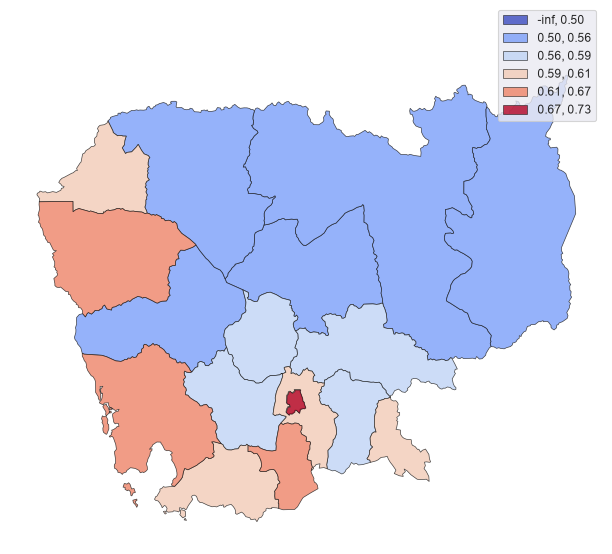

In [68]:
# Create a figure and axis for plotting
fig, ax = plt.subplots(figsize=(9, 6))

# Plot the GeoDataFrame with specified settings
gdf_INDICATOR1.plot(
    column='2019',              # Data for coloring
    scheme='BoxPlot',           # Classification scheme
    cmap='coolwarm',                # Color map for visualization
    edgecolor='k',                  # Color of edges
    linewidth=0.5,                  # Width of edge lines
    alpha=0.8,                      # Transparency
    legend=True,                    # Show legend
    ax=ax,                          # Specify the axis for plotting
    legend_kwds={'bbox_to_anchor': (1.00, 1.10)}  # Legend customization
)

# Adding a basemap using contextily
#cx.add_basemap(
    #ax,                             # Axis to add basemap to
    #crs=gdf.crs.to_string(),         # Coordinate reference system
    #source=cx.providers.Stamen.TonerHybrid,  # Basemap source
    #attribution=False               # Disable attribution
#)

# Set plot title and adjust layout
#plt.title('Spatial distribution: Three natural breaks')
plt.tight_layout()

# Turn off axis display
ax.axis("off")

# Display the plot
plt.show()

#### 5.1.2) Fisher-Jenks breaks

In [69]:
# Exploring data using the explore() function on the GeoDataFrame
gdf_INDICATOR1.explore(
    column='2019',                 # Column to visualize
    tooltip=['region'],  # Information to show in tooltip
    k=3,                               # Number of classes for visualization
    scheme='FisherJenks',              # Classification scheme (info: https://pysal.org/mapclassify/generated/mapclassify.FisherJenks.html#mapclassify.FisherJenks)
    cmap='coolwarm',                   # Color map for visualization
    legend=True,                       # Show legend
    tiles='CartoDB positron',            # Basemap style (other options: https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.explore.html)
    style_kwds=dict(color="gray", weight=0.4),  # Styling for non-highlighted areas
    legend_kwds=dict(colorbar=False)   # Legend customization
)

In [70]:
mc.FisherJenks(gdf_INDICATOR1['2019'], k=3)

FisherJenks

  Interval     Count
--------------------
[0.52, 0.58] |     8
(0.58, 0.62] |     8
(0.62, 0.73] |     1

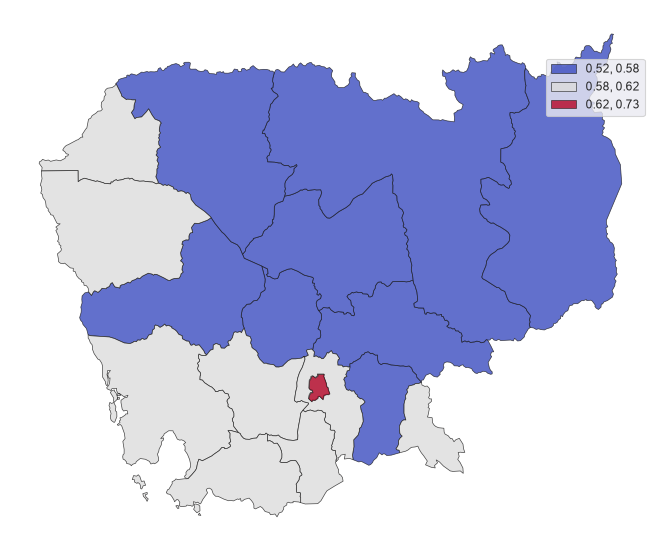

In [71]:
# Create a figure and axis for plotting
fig, ax = plt.subplots(figsize=(9, 6))

# Plot the GeoDataFrame with specified settings
gdf_INDICATOR1.plot(
    column='2019',              # Data for coloring
    scheme='FisherJenks',           # Classification scheme
    k=3,                            # Number of classes for coloring
    cmap='coolwarm',                # Color map for visualization
    edgecolor='k',                  # Color of edges
    linewidth=0.5,                  # Width of edge lines
    alpha=0.8,                      # Transparency
    legend=True,                    # Show legend
    ax=ax,                          # Specify the axis for plotting
    legend_kwds={'bbox_to_anchor': (1.00, 0.92)}  # Legend customization
)

# Adding a basemap using contextily
#cx.add_basemap(
    #ax,                             # Axis to add basemap to
    #crs=gdf.crs.to_string(),         # Coordinate reference system
    #source=cx.providers.Stamen.TonerHybrid,  # Basemap source
    #attribution=False               # Disable attribution
#)

# Set plot title and adjust layout
#plt.title('Spatial distribution: Three natural breaks')
plt.tight_layout()

# Turn off axis display
ax.axis("off")

# Display the plot
plt.show()

### 5.2) Spatial dependence

- To what extent is the performance of a region similar to that of its neighbours?
- To what extent is there is an overall pattern of "clustering"?
- Where can we find statistically significant spatial clusters?
- Where can we find statistically significant spatial outliers?

#### 5.2.1) Spatial connectivity

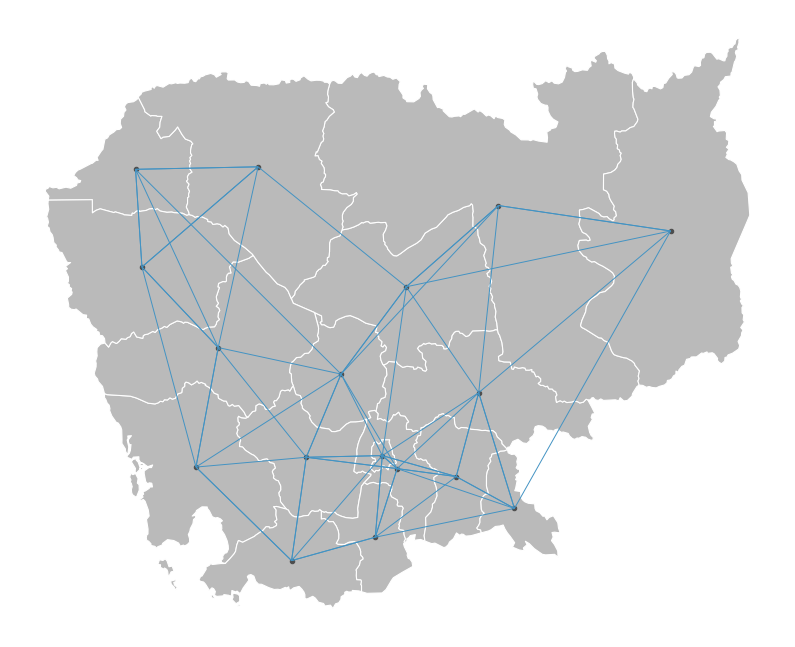

In [72]:
# Create K-nearest neighbors spatial weights
W = weights.KNN.from_dataframe(gdf, k=4)

# Transform the weights to row-standardized
W.transform = 'r'

# Plot the spatial weights using splot
plot_spatial_weights(W, gdf);

#### 5.2.2) Global dependence

In [73]:
def moran_by_col(y, w=W):
    mo = esda.Moran(y, w=w)
    mo_s = pd.Series(
        {"I": mo.I, "I-P value": mo.p_sim},
    )
    return mo_s

In [74]:
moran_dynamics_INDICATOR1 = gdf_INDICATOR1[years].apply(moran_by_col, axis=0).T
moran_dynamics_INDICATOR2 = gdf_INDICATOR2[years].apply(moran_by_col, axis=0).T
moran_dynamics_INDICATOR3 = gdf_INDICATOR3[years].apply(moran_by_col, axis=0).T
moran_dynamics_INDICATOR4 = gdf_INDICATOR4[years].apply(moran_by_col, axis=0).T
moran_dynamics_INDICATOR5 = gdf_INDICATOR5[years].apply(moran_by_col, axis=0).T
moran_dynamics_INDICATOR6 = gdf_INDICATOR6[years].apply(moran_by_col, axis=0).T
moran_dynamics_INDICATOR7 = gdf_INDICATOR7[years].apply(moran_by_col, axis=0).T

In [75]:
def plot_moran_dynamics(indicator_data):
    """
    Plot Moran's I and P-value dynamics.

    Parameters:
    - indicator_data: DataFrame or similar structure containing 'I' and 'I-P value' columns.

    Returns:
    None
    """
    # Plot 'I' values
    plt.plot(indicator_data.index, indicator_data['I'], label="Moran's I", linestyle='-')

    # Plot 'I-P value' values
    plt.plot(indicator_data.index, indicator_data['I-P value'], label='P-value', linestyle='--')

    # Adding labels and legend
    plt.xlabel("")
    plt.ylabel("Moran's I and P-value ")
    plt.legend()

    # Adjusting x-axis tick spacing
    plt.xticks(rotation=45)  # Rotate x-axis labels for better readability

    # Display the combined graph
    plt.tight_layout()  # Ensure all elements fit in the figure
    plt.show()

# Example usage: plot_moran_dynamics(moran_dynamics_INDICATOR1)

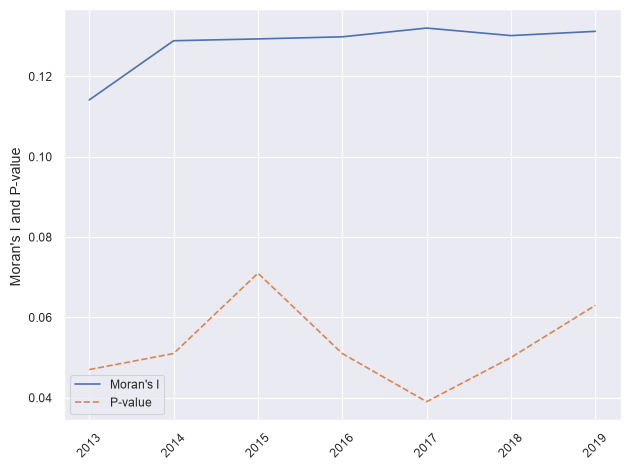

In [76]:
plot_moran_dynamics(moran_dynamics_INDICATOR1)

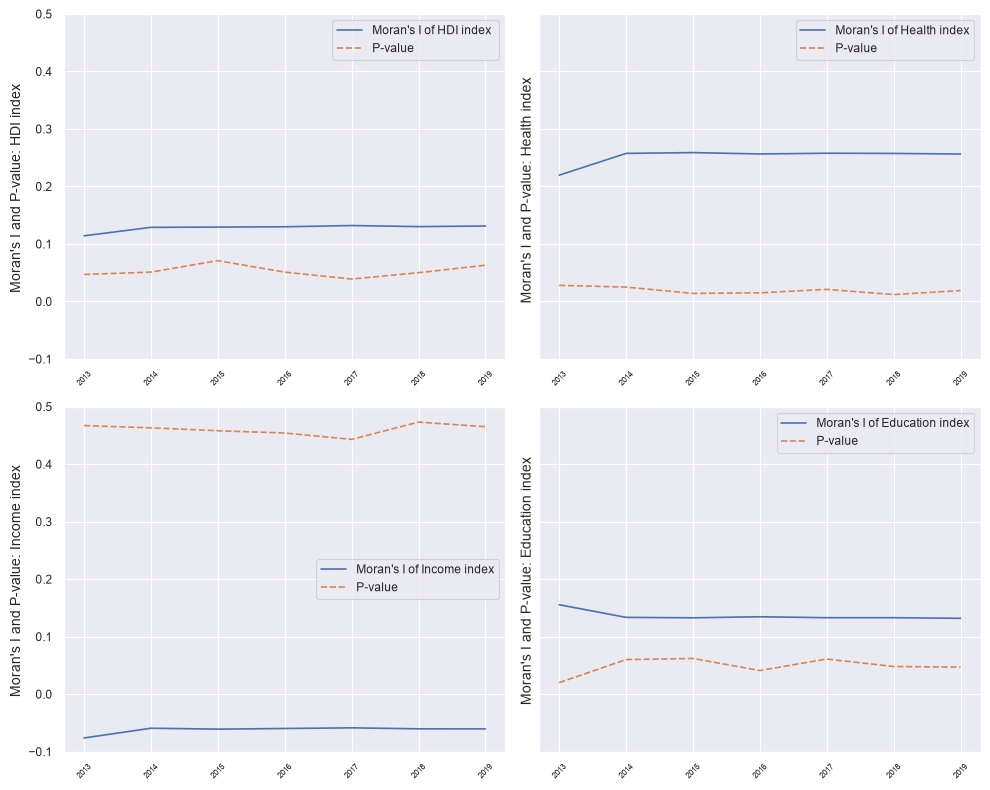

In [77]:
# Create a 2x2 subplot grid
fig, axs = plt.subplots(2, 2, figsize=(10, 8), sharey=True)  # Added sharey=True

# Set the y-axis limits for all figures
y_axis_limits = (-0.1, 0.5)

# Figure 1
axs[0, 0].plot(moran_dynamics_INDICATOR1.index, moran_dynamics_INDICATOR1['I'], label="Moran's I of HDI index ", linestyle='-')
axs[0, 0].plot(moran_dynamics_INDICATOR1.index, moran_dynamics_INDICATOR1['I-P value'], label='P-value', linestyle='--')
axs[0, 0].set_xlabel("")
axs[0, 0].set_ylabel("Moran's I and P-value: HDI index ")
axs[0, 0].legend()
axs[0, 0].tick_params(axis='x', rotation=45, labelsize=6)
axs[0, 0].set_ylim(y_axis_limits)  # Set y-axis limits

# Figure 2
axs[0, 1].plot(moran_dynamics_INDICATOR2.index, moran_dynamics_INDICATOR2['I'], label="Moran's I of Health index", linestyle='-')
axs[0, 1].plot(moran_dynamics_INDICATOR2.index, moran_dynamics_INDICATOR2['I-P value'], label='P-value', linestyle='--')
axs[0, 1].set_xlabel("")
axs[0, 1].set_ylabel("Moran's I and P-value: Health index  ")
axs[0, 1].legend()
axs[0, 1].tick_params(axis='x', rotation=45, labelsize=6)
axs[0, 1].set_ylim(y_axis_limits)  # Set y-axis limits

# Figure 3
axs[1, 0].plot(moran_dynamics_INDICATOR3.index, moran_dynamics_INDICATOR3['I'], label="Moran's I of Income index", linestyle='-')
axs[1, 0].plot(moran_dynamics_INDICATOR3.index, moran_dynamics_INDICATOR3['I-P value'], label='P-value', linestyle='--')
axs[1, 0].set_xlabel("")
axs[1, 0].set_ylabel("Moran's I and P-value: Income index ")
axs[1, 0].legend()
axs[1, 0].tick_params(axis='x', rotation=45, labelsize=6)
axs[1, 0].set_ylim(y_axis_limits)  # Set y-axis limits

# Figure 4
axs[1, 1].plot(moran_dynamics_INDICATOR4.index, moran_dynamics_INDICATOR4['I'], label="Moran's I of Education index", linestyle='-')
axs[1, 1].plot(moran_dynamics_INDICATOR4.index, moran_dynamics_INDICATOR4['I-P value'], label='P-value', linestyle='--')
axs[1, 1].set_xlabel("")
axs[1, 1].set_ylabel("Moran's I and P-value: Education index ")
axs[1, 1].legend()
axs[1, 1].tick_params(axis='x', rotation=45, labelsize=6)
axs[1, 1].set_ylim(y_axis_limits)  # Set y-axis limits

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()

#### 5.2.3) Local dependence

In [78]:
def visualize_spatial_association(gdf_INDICATOR, W, year):
    """
    Visualize spatial association using Moran's I and Local Indicators of Spatial Association (LISA).

    Parameters:
    - gdf_INDICATOR: GeoDataFrame containing the indicator data for the specified year.
    - W: Spatial weights matrix.
    - year: The specific year for which spatial association is visualized.

    Returns:
    None
    """
    # Calculate global Moran's I
    globalMoran_INDICATOR = Moran(gdf_INDICATOR[year], W)
    MoranI_INDICATOR = "{:.2f}".format(globalMoran_INDICATOR.I)

    # Calculate local indicators of spatial association
    localMoran_INDICATOR = Moran_Local(gdf_INDICATOR[year], W, permutations=999, seed=12345)

    # Create subplots for visualizations
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

    # Plotting Moran scatterplot
    moran_scatterplot(localMoran_INDICATOR, p=0.10, aspect_equal=False, zstandard=False, ax=axes[0])

    # Plotting Local Indicators of Spatial Association (LISA) clusters
    lisa_cluster(localMoran_INDICATOR, gdf_INDICATOR, p=0.10, legend_kwds={'bbox_to_anchor': (0.02, 0.90)}, ax=axes[1])

    # Setting labels and titles for the plots
    axes[0].set_xlabel('Indicator')
    axes[0].set_ylabel('Spatial lag of indicator')
    axes[0].set_title(f"(a) Moran scatterplot (Moran's I = {MoranI_INDICATOR})")
    axes[1].set_title("(b) Spatial clusters and outliers (p < 0.10)")

    # Display the plots
    plt.show()

# Example usage: visualize_spatial_association(gdf_INDICATOR1, W, '2019')

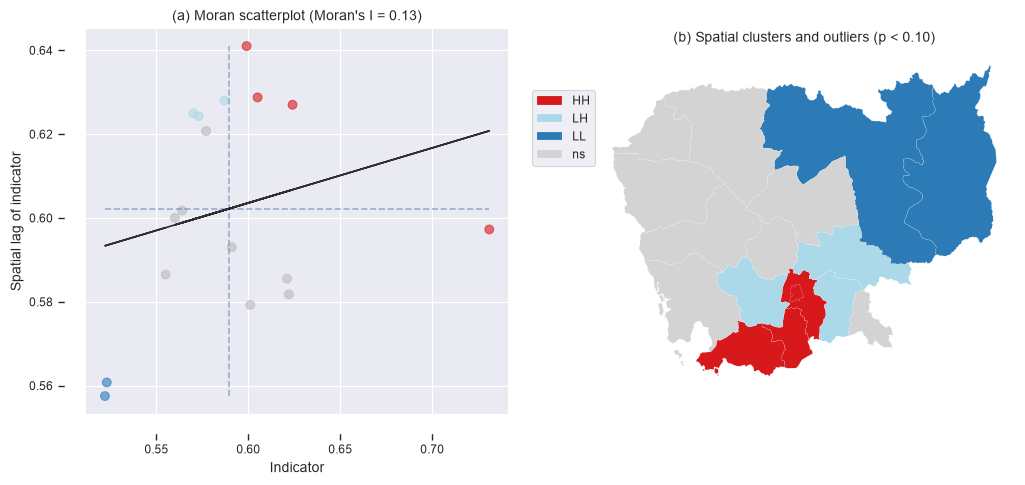

In [79]:
visualize_spatial_association(gdf_INDICATOR1, W, '2019')

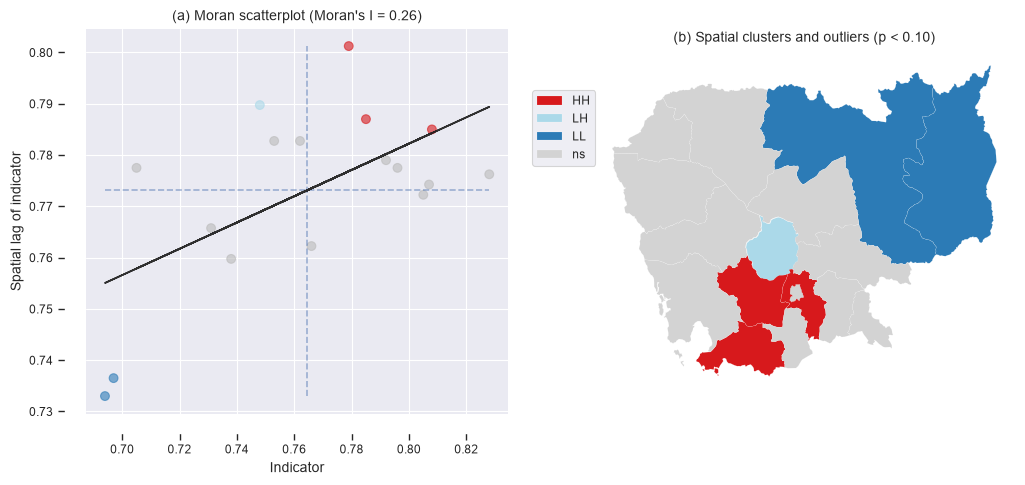

In [80]:
visualize_spatial_association(gdf_INDICATOR2, W, '2019')

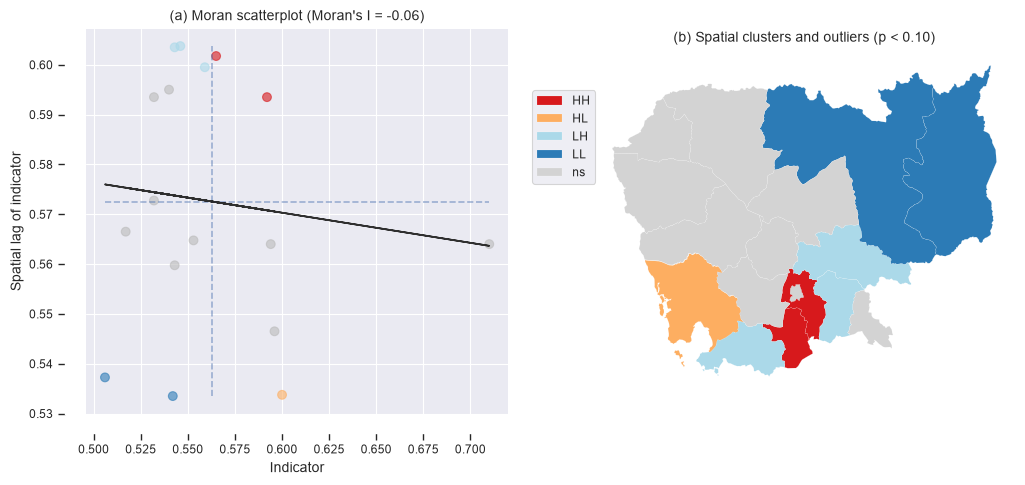

In [81]:
visualize_spatial_association(gdf_INDICATOR3, W, '2019')

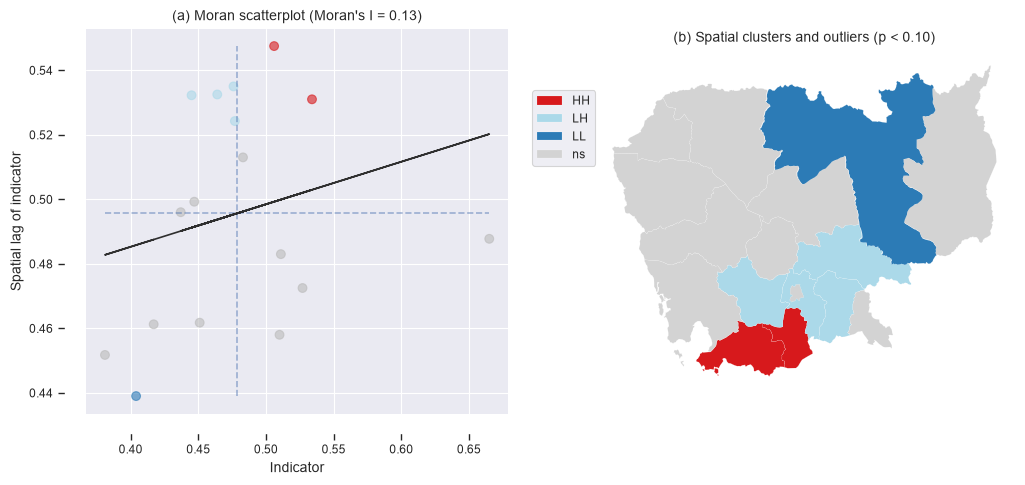

In [82]:
visualize_spatial_association(gdf_INDICATOR4, W, '2019')

### 5.3) Spatial inequality

#### 5.3.1) Theil index

In [83]:
# Defining a function to return the Their index of a data frame column
def theil_by_col(column):
    return inequality.theil.Theil(column.values).T

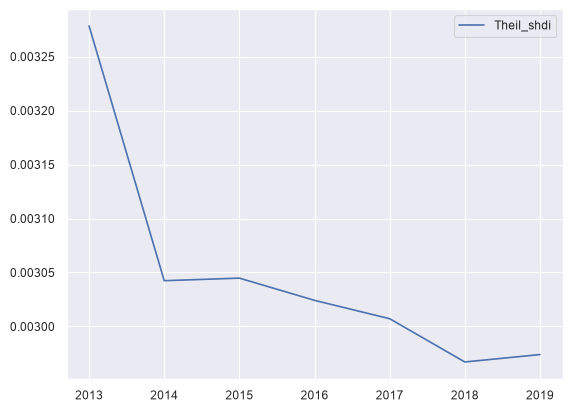

In [84]:
# Computing Theil index for each column of the data frame
theil_INDICATOR1  = gdf_INDICATOR1[years].apply(theil_by_col, axis=0).to_frame("Theil_"+INDICATOR1)
theil_INDICATOR1.plot();

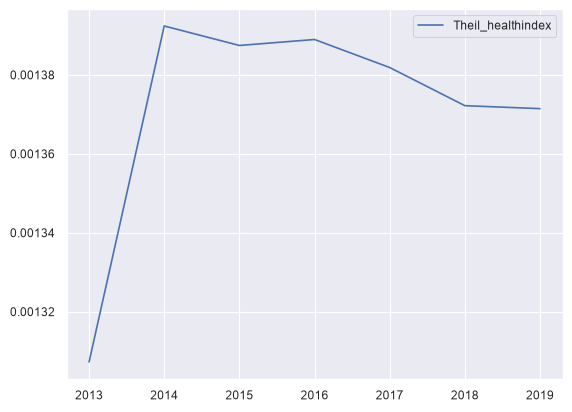

In [85]:
theil_INDICATOR2  = gdf_INDICATOR2[years].apply(theil_by_col, axis=0).to_frame("Theil_"+INDICATOR2)
theil_INDICATOR2.plot();

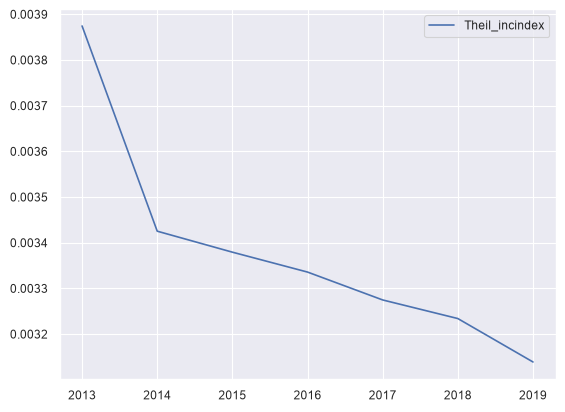

In [86]:
theil_INDICATOR3  = gdf_INDICATOR3[years].apply(theil_by_col, axis=0).to_frame("Theil_"+INDICATOR3)
theil_INDICATOR3.plot();

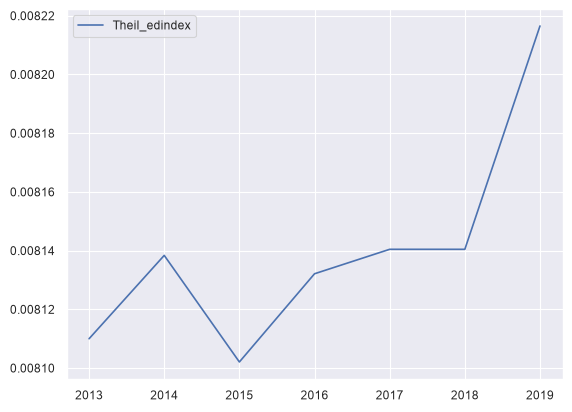

In [87]:
theil_INDICATOR4  = gdf_INDICATOR4[years].apply(theil_by_col, axis=0).to_frame("Theil_"+INDICATOR4)
theil_INDICATOR4.plot();

#### 5.3.2) Gini index

In [88]:
# Defining a function to return the Gini coefficient of a data frame column
def gini_by_col(column):
    return inequality.gini.Gini(column.values).g

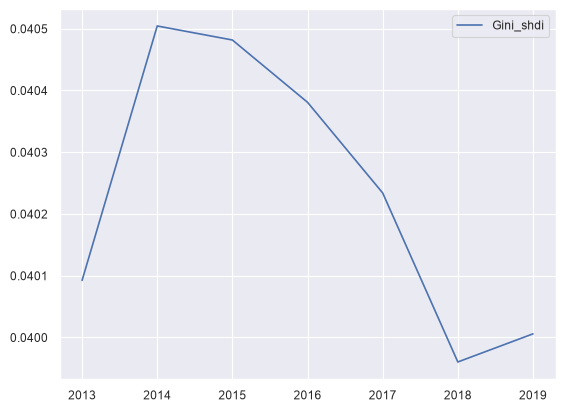

In [89]:
# Computing Gini index for each column of the data frame
gini_INDICATOR1 = gdf_INDICATOR1[years].apply(gini_by_col, axis=0).to_frame("Gini_"+INDICATOR1)
gini_INDICATOR1.plot();

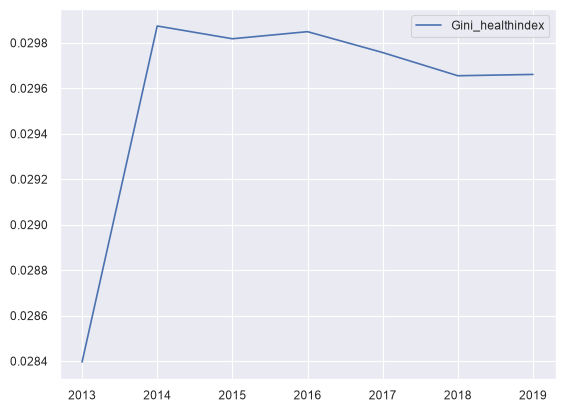

In [90]:
gini_INDICATOR2 = gdf_INDICATOR2[years].apply(gini_by_col, axis=0).to_frame("Gini_"+INDICATOR2)
gini_INDICATOR2.plot();

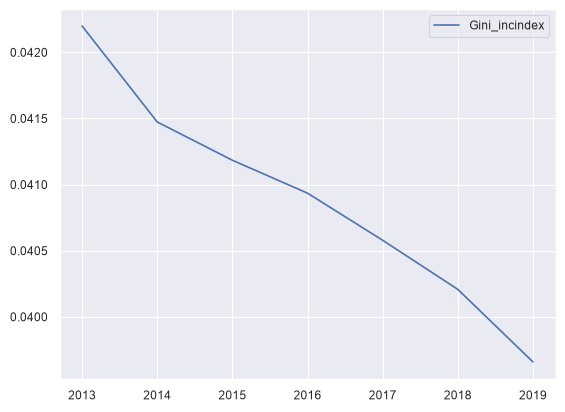

In [91]:
gini_INDICATOR3 = gdf_INDICATOR3[years].apply(gini_by_col, axis=0).to_frame("Gini_"+INDICATOR3)
gini_INDICATOR3.plot();

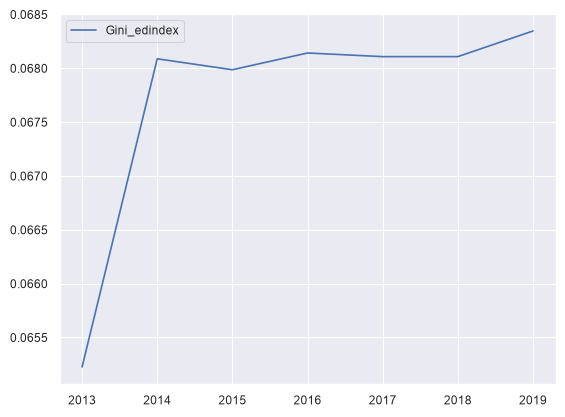

In [92]:
gini_INDICATOR4 = gdf_INDICATOR4[years].apply(gini_by_col, axis=0).to_frame("Gini_"+INDICATOR4)
gini_INDICATOR4.plot();

Let's compute the spatial gini index

In [93]:
Gini_Spatial(gdf_INDICATOR1['2019'], W).wcg_share

np.float64(0.030400468086579664)

In [94]:
Gini_Spatial(gdf_INDICATOR1['2019'], W).p_sim

np.float64(0.27)

# 6) Analysis of satellite NTL images

## Processing satellite images

In [95]:
# Download only the rasters of the years analysed, one file at a time, through the figshare API.
# (The whole archive is 1.2 GB, and figshare prepares it asynchronously: the zip URL first answers
# "202 Accepted" with no content, so downloading it in one request fails.)
api = "https://api.figshare.com/v2/articles/9828827/versions/7"
os.makedirs("my_extracted_files", exist_ok=True)
for f in requests.get(api, timeout=60).json()["files"]:
    if any(f["name"].startswith(f"Harmonized_DN_NTL_{year}_") for year in range(startYear, endYear + 1)):
        path = os.path.join("my_extracted_files", f["name"])
        if not os.path.exists(path):
            response = requests.get(f["download_url"], timeout=600)
            response.raise_for_status()
            with open(path, "wb") as out:
                out.write(response.content)
        print("Ready:", f["name"])

Ready: Harmonized_DN_NTL_2014_simVIIRS.tif


Ready: Harmonized_DN_NTL_2015_simVIIRS.tif


Ready: Harmonized_DN_NTL_2016_simVIIRS.tif


Ready: Harmonized_DN_NTL_2017_simVIIRS.tif


Ready: Harmonized_DN_NTL_2018_simVIIRS.tif


Ready: Harmonized_DN_NTL_2013_calDMSP.tif


Ready: Harmonized_DN_NTL_2019_simVIIRS.tif


In [96]:
RASTER_DIRECTORY = "my_extracted_files"

In [97]:
def load_raster(year):
    # Function to open the raster file of a given year. Works for years before and after 2013.
    raster_path = f"{RASTER_DIRECTORY}/Harmonized_DN_NTL_{year}*"
    return (rasterio.open(glob.glob(raster_path)[0]))

In [98]:
MAPurl = "gdf.geojson"

In [99]:
# The boundaries of Cambodia's GDL regions are stored in gdf.geojson. The file is loaded using the read_file function from geopandas
polygonsFile = gpd.read_file(MAPurl)

# The bounding box of the vector file previously loaded is extracted using the total_bounds property
polygonsFile_bbox = polygonsFile.total_bounds

In [100]:
# The raster file corresponding to the start year is loaded using the open function in rasterio
rasterFileFirst = load_raster(startYear)
# rasterFileFirst = rasterio.open("my_extracted_files/Harmonized_DN_NTL_"+str(startYear)+"_simVIIRS.tif")

# The bounding box of the vector data is used to crop the raster file
rasterFile_windowFirst  = rasterFileFirst.window(*polygonsFile_bbox)
rasterFile_clippedFirst = rasterFileFirst.read(1, window = rasterFile_windowFirst)

In [101]:
# The raster file corresponding to the start year is loaded using the open function in rasterio
rasterFileLast = load_raster(endYear)

# The bounding box of the vector data is used to crop the raster file
rasterFile_windowLast  = rasterFileLast.window(*polygonsFile_bbox)
rasterFile_clippedLast = rasterFileLast.read(1, window = rasterFile_windowLast)

In [102]:
# A dataframe is initialised to store the results
gdf_NTL = polygonsFile.copy()

In [103]:
# A loop runs from the start year to the end year that computes the aggregate nighttime lights radiance for each state
for year in range(startYear, endYear + 1):
    # The raster file of the given year is loaded
    rasterFile = load_raster(year)
    # A mask is a created using the geometry provided in the vector file
    def clean_mask(geom, dataset=rasterFile, **mask_kw):
        mask_kw.setdefault("crop", True)
        mask_kw.setdefault("all_touched", True)
        masked, mask_transform = mask(dataset=dataset, shapes=(geom,),
                                    **mask_kw)
        return masked
    # The mask is a applied and then a summation is performed for computing the aggregate radiance.
    statewise_agg_ntl = polygonsFile.geometry.apply(clean_mask).apply(np.ma.sum)
    # The state wise aggregate radiance of the year is stored in the data frame that was initialised earlier.
    gdf_NTL[str(year)] = statewise_agg_ntl

In [104]:
gdf_NTL

,GDLcode,region,geometry,2013,2014,2015,2016,2017,2018,2019
0,KHMr101,Banteay Mean Chey,"MULTIPOLYGON (((103.41805 13.36454, 103.40022 ...",1975,12207,19113,21903,39862,32660,37052
1,KHMr102,Kampong Cham (incl Tboung Khmum),"MULTIPOLYGON (((105.80955 11.59948, 105.76749 ...",3367,14960,18105,23369,27611,42945,42308
2,KHMr103,Kampong Chhnang,"MULTIPOLYGON (((104.2008 12.07537, 104.18831 1...",786,8173,8264,11790,15024,21858,24439
3,KHMr104,Kampong Spueu,"MULTIPOLYGON (((104.41069 11.13689, 104.3981 1...",3265,18744,23653,27329,26897,39726,39623
4,KHMr105,Kampong Thum,"MULTIPOLYGON (((104.87311 12.23806, 104.85906 ...",3072,14419,20944,26838,20823,35832,31753
5,KHMr106,Kandal,"MULTIPOLYGON (((105.03613 10.89576, 105.03212 ...",30067,33567,39864,39845,50369,56079,66575
6,KHMr107,Kaoh Kong,"MULTIPOLYGON (((103.31796 10.62123, 103.3189 1...",1911,16794,17641,17682,19966,26079,26068
7,KHMr108,Phnom Penh,"MULTIPOLYGON (((104.78944 11.48629, 104.80135 ...",17502,15424,16207,17437,19250,20458,23863
8,KHMr109,Prey Veaeng,"MULTIPOLYGON (((105.61271 10.97337, 105.53631 ...",756,4166,6963,7169,15517,21674,20896
9,KHMr110,Pousat,"MULTIPOLYGON (((103.85887 11.84183, 103.84345 ...",583,18294,15937,33308,24179,33281,43614


In [105]:
gdf_NTL.to_file("gdf_NTL.geojson", driver="GeoJSON")

In [106]:
# Create long dataframe of NTL
dfWIDE_NTL = gpd.read_file("gdf_NTL.geojson").drop("geometry", axis=1)
dfLONG_NTL = pd.melt(dfWIDE_NTL, id_vars= ["GDLcode", "region"], value_vars=[str(x) for x in range(startYear,endYear +1)])
dfLONG_NTL.columns = ["GDLcode", "region", "year", "NTL"]

In [107]:
dfLONG_NTL

,GDLcode,region,year,NTL
0,KHMr101,Banteay Mean Chey,2013,1975
1,KHMr102,Kampong Cham (incl Tboung Khmum),2013,3367
2,KHMr103,Kampong Chhnang,2013,786
3,KHMr104,Kampong Spueu,2013,3265
4,KHMr105,Kampong Thum,2013,3072
...,...,...,...,...
114,KHMr113,Bat Dambang-Krong Pailin,2019,55644
115,KHMr114,Kampot-Krong Kaeb-Krong Preah Sihanouk,2019,47704
116,KHMr115,Preah Vihear-Stueng Traeng-Kracheh,2019,190571
117,KHMr116,Mondol Kiri-Rotanak Kiri,2019,143269


In [108]:
# Merge with other indicators
df_NTL_HDI = pd.merge(dfLONG_NTL, df1_INDICATOR1, on=["GDLcode", "region", "year"], how="inner")
df_NTL_HDI = pd.merge(df_NTL_HDI, df1_INDICATOR5, on=["GDLcode", "region", "year"], how="inner")
df_NTL_HDI = pd.merge(df_NTL_HDI, df1_INDICATOR7, on=["GDLcode", "region", "year"], how="inner")

In [109]:
df_NTL_HDI["lnNTL"] = np.log(0.01 + df_NTL_HDI["NTL"])

In [110]:
df_NTL_HDI["lnNTLpc"] = np.log((0.01 + df_NTL_HDI["NTL"])*100000000/df_NTL_HDI["pop"])

In [111]:
df_NTL_HDI["lnGNI"] = np.log(df_NTL_HDI["gnic"]*df_NTL_HDI["pop"])

In [112]:
df_NTL_HDI["GNI"] = df_NTL_HDI["gnic"]*df_NTL_HDI["pop"]

In [113]:
# gnic is already per capita: its log is log GNI per capita
df_NTL_HDI["lnGNIpc"] = np.log(df_NTL_HDI["gnic"])

In [114]:
df_NTL_HDI

,GDLcode,region,year,NTL,shdi,pop,gnic,lnNTL,lnNTLpc,lnGNI,GNI,lnGNIpc
0,KHMr101,Banteay Mean Chey,2013,1975,0.557,642.362,3574.3821,7.588329,19.543857,14.646700,2.296047e+06,8.181548
1,KHMr102,Kampong Cham (incl Tboung Khmum),2013,3367,0.535,1908.256,2624.5850,8.121780,18.988516,15.426623,5.008380e+06,7.872678
2,KHMr103,Kampong Chhnang,2013,786,0.535,548.755,2433.4170,6.666970,18.779998,14.104704,1.335350e+06,7.797052
3,KHMr104,Kampong Spueu,2013,3265,0.552,931.555,2580.7029,8.091018,19.674844,14.692672,2.404067e+06,7.855817
4,KHMr105,Kampong Thum,2013,3072,0.525,754.969,2457.4690,8.030087,19.824091,14.433564,1.855313e+06,7.806887
...,...,...,...,...,...,...,...,...,...,...,...,...
114,KHMr113,Bat Dambang-Krong Pailin,2019,55644,0.621,1282.818,5092.4541,10.926730,22.190596,15.692330,6.532692e+06,8.535515
115,KHMr114,Kampot-Krong Kaeb-Krong Preah Sihanouk,2019,47704,0.599,995.952,3713.3811,10.772771,22.289752,15.123397,3.698349e+06,8.219698
116,KHMr115,Preah Vihear-Stueng Traeng-Kracheh,2019,190571,0.522,899.835,2851.8450,12.157780,23.776249,14.757933,2.566190e+06,7.955721
117,KHMr116,Mondol Kiri-Rotanak Kiri,2019,143269,0.523,350.669,3608.5071,11.872479,24.433317,14.050892,1.265392e+06,8.191049


In [115]:
# Saving the long form tabular data to a csv file
df_NTL_HDI.to_csv("df_NTL_HDI.csv", index = False)

In [116]:
df_NTL_HDI.describe()

,NTL,shdi,pop,gnic,lnNTL,lnNTLpc,lnGNI,GNI,lnGNIpc
count,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,1.190000e+02,119.000000
mean,35324.764706,0.570303,927.179109,3670.997838,9.945258,21.703199,14.811208,3.588975e+06,8.148467
std,39915.145234,0.046873,450.144611,1563.631203,1.131903,1.294048,0.781715,3.008503e+06,0.317984
min,583.000000,0.487000,84.621000,2113.563000,6.368204,18.086505,12.720996,3.347022e+05,7.656130
25%,15224.000000,0.542500,606.555000,2807.778600,9.630543,21.045327,14.401604,1.797034e+06,7.940149
50%,21903.000000,0.566000,937.650000,3229.226100,9.994379,21.703680,14.874579,2.883682e+06,8.079998
75%,39651.500000,0.590500,1214.154500,3913.410500,10.587884,22.278344,15.289736,4.368110e+06,8.272137
max,220967.000000,0.731000,2146.548000,11014.653000,12.305769,24.628359,16.651011,1.703892e+07,9.306982


In [117]:
# Saving the long form tabular data to a csv file
df_NTL_HDI.to_csv("df_NTL_HDI.csv", index = False)

In [118]:
# Pivot panel data from long form to wide form
dfWIDE_lnNTL = df_NTL_HDI.pivot_table(
    index=["GDLcode", "region"],
    columns="year",
    values="lnNTL").reset_index(drop=False)
# Make sure the column names are strings
dfWIDE_lnNTL.columns = dfWIDE_lnNTL.columns.astype(str)

In [119]:
# Merge with polygonsFile
gdf_lnNTL = pd.merge(polygonsFile, dfWIDE_lnNTL, left_on= ["GDLcode", "region"], right_on= ["GDLcode", "region"], how="inner")
gdf_lnNTL

,GDLcode,region,geometry,2013,2014,2015,2016,2017,2018,2019
0,KHMr101,Banteay Mean Chey,"MULTIPOLYGON (((103.41805 13.36454, 103.40022 ...",7.588329,9.409766,9.858125,9.994379,10.593179,10.393907,10.520078
1,KHMr102,Kampong Cham (incl Tboung Khmum),"MULTIPOLYGON (((105.80955 11.59948, 105.76749 ...",8.121780,9.613136,9.803944,10.059166,10.225970,10.667676,10.652732
2,KHMr103,Kampong Chhnang,"MULTIPOLYGON (((104.2008 12.07537, 104.18831 1...",6.666970,9.008593,9.019665,9.375008,9.617405,9.992323,10.103936
3,KHMr104,Kampong Spueu,"MULTIPOLYGON (((104.41069 11.13689, 104.3981 1...",8.091018,9.838630,10.071246,10.215704,10.199770,10.589761,10.587165
4,KHMr105,Kampong Thum,"MULTIPOLYGON (((104.87311 12.23806, 104.85906 ...",8.030087,9.576303,9.949608,10.197574,9.943814,10.486597,10.365743
5,KHMr106,Kandal,"MULTIPOLYGON (((105.03613 10.89576, 105.03212 ...",10.311184,10.421299,10.593229,10.592752,10.827131,10.934517,11.106085
6,KHMr107,Kaoh Kong,"MULTIPOLYGON (((103.31796 10.62123, 103.3189 1...",7.555387,9.728778,9.777982,9.780303,9.901787,10.168886,10.168464
7,KHMr108,Phnom Penh,"MULTIPOLYGON (((104.78944 11.48629, 104.80135 ...",9.770071,9.643681,9.693199,9.766350,9.865267,9.926130,10.080085
8,KHMr109,Prey Veaeng,"MULTIPOLYGON (((105.61271 10.97337, 105.53631 ...",6.628055,8.334714,8.848367,8.877523,9.649692,9.983869,9.947314
9,KHMr110,Pousat,"MULTIPOLYGON (((103.85887 11.84183, 103.84345 ...",6.368204,9.814329,9.676399,10.413553,10.093240,10.412742,10.683134


In [120]:
# Writing the geo data frame of state wise log nighttime lights to a geojson file.
gdf_lnNTL.to_file("gdf_lnNTL.geojson", driver="GeoJSON")

In [121]:
# Pivot panel data from long form to wide form
dfWIDE_lnNTLpc = df_NTL_HDI.pivot_table(
    index=["GDLcode", "region"],
    columns="year",
    values="lnNTLpc").reset_index(drop=False)
# Make sure the column names are strings
dfWIDE_lnNTLpc.columns = dfWIDE_lnNTLpc.columns.astype(str)
# Merge with polygonsFile
gdf_lnNTLpc = pd.merge(polygonsFile, dfWIDE_lnNTLpc, left_on= ["GDLcode", "region"], right_on= ["GDLcode", "region"], how="inner")
gdf_lnNTLpc.to_file("gdf_lnNTLpc.geojson", driver="GeoJSON")

In [122]:
# Pivot panel data from long form to wide form
dfWIDE_GNI = df_NTL_HDI.pivot_table(
    index=["GDLcode", "region"],
    columns="year",
    values="GNI").reset_index(drop=False)
# Make sure the column names are strings
dfWIDE_GNI.columns = dfWIDE_GNI.columns.astype(str)
# Merge with polygonsFile
gdf_GNI = pd.merge(polygonsFile, dfWIDE_GNI, left_on= ["GDLcode", "region"], right_on= ["GDLcode", "region"], how="inner")
gdf_GNI.to_file("gdf_GNI.geojson", driver="GeoJSON")

In [123]:
# Pivot panel data from long form to wide form
dfWIDE_lnGNIpc = df_NTL_HDI.pivot_table(
    index=["GDLcode", "region"],
    columns="year",
    values="lnGNIpc").reset_index(drop=False)
# Make sure the column names are strings
dfWIDE_lnGNIpc.columns = dfWIDE_lnGNIpc.columns.astype(str)
# Merge with polygonsFile
gdf_lnGNIpc = pd.merge(polygonsFile, dfWIDE_lnGNIpc, left_on= ["GDLcode", "region"], right_on= ["GDLcode", "region"], how="inner")
gdf_lnGNIpc.to_file("gdf_lnGNIpc.geojson", driver="GeoJSON")

## Visualizing NTL

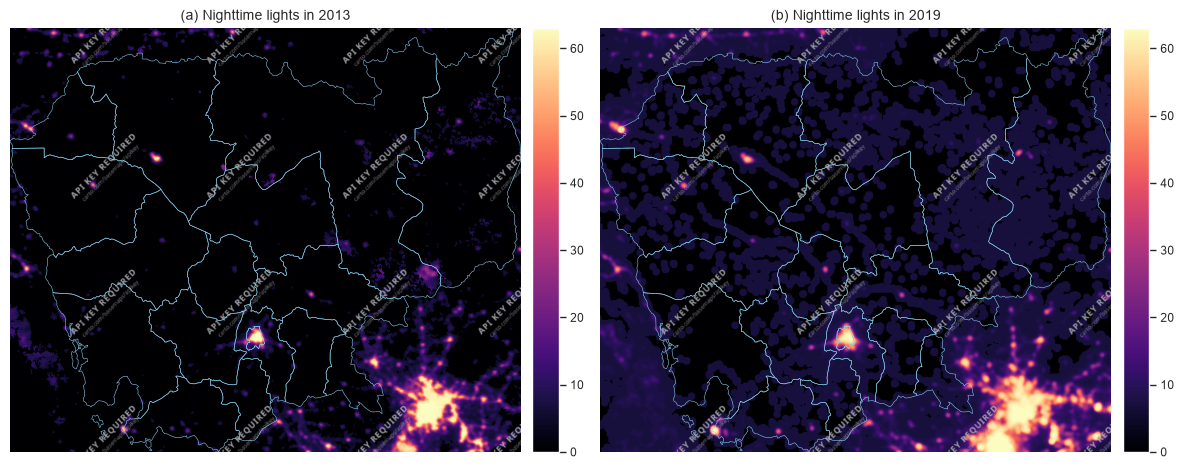

In [124]:
# A figure is initialized with 2 plots.
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,8))

# The night-time lights around Cambodia in the start year are added
im1 = ax1.imshow(rasterFile_clippedFirst, extent=polygonsFile_bbox[[0,2,1,3]], vmin=0, vmax=63, cmap="magma")
# State boundaries are overlayed
polygonsFile.boundary.plot(ax=ax1, color="skyblue", linewidth = 0.4)
# Axis is added
cx.add_basemap(ax=ax1, crs=polygonsFile.crs.to_string(), source = cx.providers.CartoDB.DarkMatterOnlyLabels, attribution=False)

divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", size="5%", pad=0.05)
cbar1 = plt.colorbar(im1, cax=cax1)

ax1.set_xlabel("Longitude")
ax1.set_ylabel("Latitude")
# Title of the plot is added
ax1.set_title("(a) Nighttime lights in " + str(startYear))
ax1.set_axis_off()

# The night-time lights around Cambodia in the last year are plotted
im2 = ax2.imshow(rasterFile_clippedLast, extent=polygonsFile_bbox[[0,2,1,3]], vmin=0, vmax=63, cmap="magma")
# State boundaries are overlayed
polygonsFile.boundary.plot(ax=ax2, color="skyblue", linewidth = 0.4)
# Axis is added
cx.add_basemap(ax=ax2, crs=polygonsFile.crs.to_string(), source = cx.providers.CartoDB.DarkMatterOnlyLabels, attribution=False)

divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", size="5%", pad=0.05)
cbar2 = plt.colorbar(im2, cax=cax2)

ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
# Title of the plot is added

ax2.set_title("(b) Nighttime lights in "+str(endYear))
ax2.set_axis_off()

plt.tight_layout()
plt.savefig("NTL.png",dpi=300, bbox_inches="tight")
plt.show()

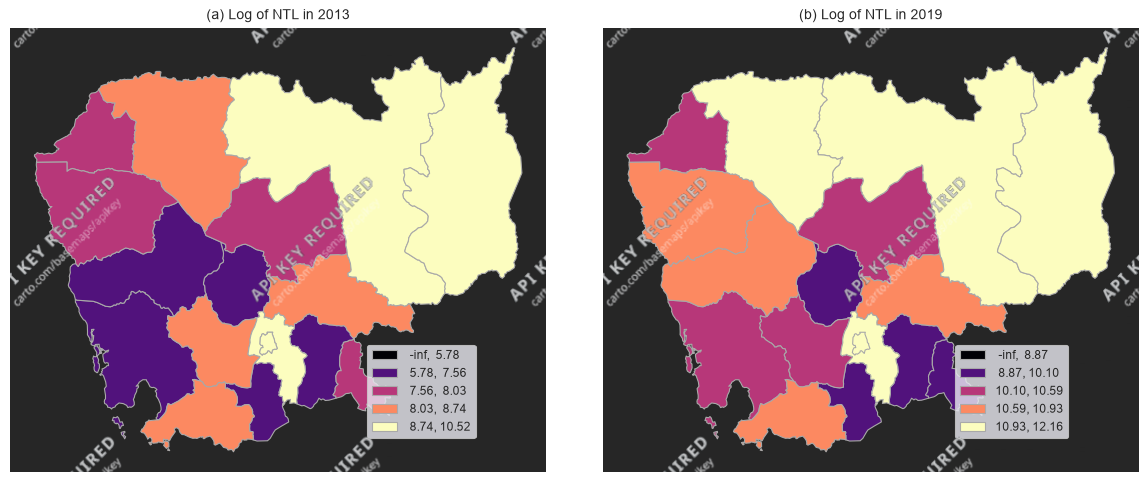

In [125]:
# Static plot of (log) NTL for the initial and final year

# A figure is initialized
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,8))

# The plot of the start year is added
gdf_lnNTL.plot(column= str(startYear), scheme="BoxPlot", cmap="magma", edgecolor="darkgrey", legend=True, ax=axes[0], legend_kwds={"bbox_to_anchor":(0.88, 0.30)})
cx.add_basemap(ax=axes[0], crs=gdf_lnNTL.crs.to_string(), source = cx.providers.CartoDB.DarkMatterNoLabels,  attribution=False)
cx.add_basemap(ax=axes[0], crs=gdf_lnNTL.crs.to_string(), source = cx.providers.CartoDB.DarkMatterOnlyLabels,  attribution=False)

# The plot of the end year is added.
gdf_lnNTL.plot(column= str(endYear),  scheme="BoxPlot", classification_kwds={"bins":[1, 2, 4, 16]}, cmap="magma", edgecolor="darkgrey", legend=True, ax=axes[1], legend_kwds={"bbox_to_anchor":(0.88, 0.30)})
cx.add_basemap(ax=axes[1], crs=gdf_lnNTL.crs.to_string(), source = cx.providers.CartoDB.DarkMatterNoLabels,  attribution=False)
cx.add_basemap(ax=axes[1], crs=gdf_lnNTL.crs.to_string(), source = cx.providers.CartoDB.DarkMatterOnlyLabels,  attribution=False)

plt.tight_layout()
axes[0].axis("off")
axes[1].axis("off")
axes[0].set_title("(a) Log of NTL in " + str(startYear))
axes[1].set_title("(b) Log of NTL in " + str(endYear))

#plt.savefig("fig_map_lnNTL.png",dpi=300, bbox_inches="tight")
plt.show()

In [126]:
fig0 = px.line(df_NTL_HDI, x = "year", y = "lnNTLpc", color = "region")
fig0.show(renderer="colab")

In [127]:
# Regional time series of (log) nighttime lights
fig0 = px.line(df_NTL_HDI, x = "year", y = "lnNTL", color = "region")
fig0.show(renderer="colab")

## Exploring NTL and GNI

In [128]:
df_NTL_HDI

,GDLcode,region,year,NTL,shdi,pop,gnic,lnNTL,lnNTLpc,lnGNI,GNI,lnGNIpc
0,KHMr101,Banteay Mean Chey,2013,1975,0.557,642.362,3574.3821,7.588329,19.543857,14.646700,2.296047e+06,8.181548
1,KHMr102,Kampong Cham (incl Tboung Khmum),2013,3367,0.535,1908.256,2624.5850,8.121780,18.988516,15.426623,5.008380e+06,7.872678
2,KHMr103,Kampong Chhnang,2013,786,0.535,548.755,2433.4170,6.666970,18.779998,14.104704,1.335350e+06,7.797052
3,KHMr104,Kampong Spueu,2013,3265,0.552,931.555,2580.7029,8.091018,19.674844,14.692672,2.404067e+06,7.855817
4,KHMr105,Kampong Thum,2013,3072,0.525,754.969,2457.4690,8.030087,19.824091,14.433564,1.855313e+06,7.806887
...,...,...,...,...,...,...,...,...,...,...,...,...
114,KHMr113,Bat Dambang-Krong Pailin,2019,55644,0.621,1282.818,5092.4541,10.926730,22.190596,15.692330,6.532692e+06,8.535515
115,KHMr114,Kampot-Krong Kaeb-Krong Preah Sihanouk,2019,47704,0.599,995.952,3713.3811,10.772771,22.289752,15.123397,3.698349e+06,8.219698
116,KHMr115,Preah Vihear-Stueng Traeng-Kracheh,2019,190571,0.522,899.835,2851.8450,12.157780,23.776249,14.757933,2.566190e+06,7.955721
117,KHMr116,Mondol Kiri-Rotanak Kiri,2019,143269,0.523,350.669,3608.5071,11.872479,24.433317,14.050892,1.265392e+06,8.191049


In [129]:
fig1 = px.line(df_NTL_HDI, x = "year", y = "lnGNI", color = "region")
fig1.show(renderer="colab")

In [130]:
fig1 = px.line(df_NTL_HDI, x = "year", y = "lnNTL", color = "region")
fig1.show(renderer="colab")

In [131]:
# Interactive scatter plot and regression line of the NTL-GDP relationship
fig3 = px.scatter(data_frame= df_NTL_HDI,
                                x = "lnNTL",
                                y = "lnGNI",
                                #range_x = [6, 16.5],
                                #range_y = [12, 22],
                                hover_name ="region",
                                #text = "selectedRegion",
                                animation_frame = "year",
                                trendline ="ols",
                                #marginal_x = "histogram",
                                #marginal_y =" histogram"
                                )

fig3.show(renderer="colab")

In [132]:
# Interactive scatter plot and regression line of the NTL-GDP relationship
fig4 = px.scatter(data_frame= df_NTL_HDI,
                                x = "lnNTL",
                                y = "lnGNI",
                                #range_x = [6, 16.5],
                                #range_y = [12, 22],
                                hover_name ="region",
                                #text = "selectedRegion",
                                #animation_frame = "year",
                                trendline ="ols",
                                #marginal_x = "histogram",
                                #marginal_y =" histogram"
                                )

fig4.show(renderer="colab")

## NTL-GNI panel relationship

In [133]:
# Setup the panel data indices
#df_panel = pd.read_csv("df_NTL_HDI.csv").set_index(["region", "year"])
#df_panel

In [134]:
# Performing panel data regressions to find the relationship between nighttime lights and subnational GDP.
#table = {
#    "(1) Pooled":    PooledOLS.from_formula(formula  = "lnGNI ~ 1 + lnNTL", data=df_panel).fit(cov_type="clustered"),
#    "(2) Within":    PanelOLS.from_formula(formula   = "lnGNI ~ 1 + lnNTL + EntityEffects + TimeEffects",  drop_absorbed=True, data=df_panel).fit(cov_type="clustered"),
#    "(3) Between":   BetweenOLS.from_formula(formula = "lnGNI ~ 1 + lnNTL", data=df_panel).fit(cov_type="clustered"),
#}

In [135]:
# Generating a summary table of the regressions.
#compare(table).summary

## NTL and GNI inequality dynamics

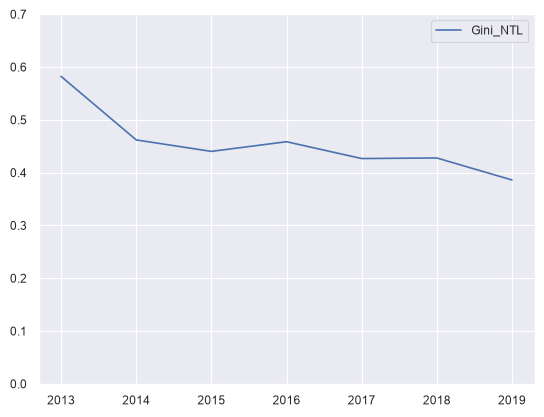

In [136]:
ax = gdf_NTL[years].apply(gini_by_col, axis=0).to_frame("Gini_NTL").plot()
ax.set_ylim(0, 0.70)
plt.show()

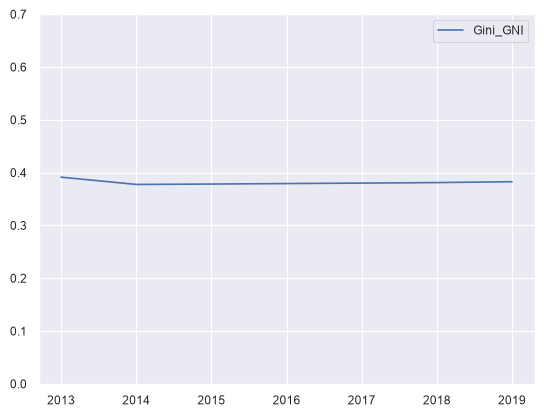

In [137]:
ax = gdf_GNI[years].apply(gini_by_col, axis=0).to_frame("Gini_GNI").plot()
ax.set_ylim(0, 0.70)
plt.show()

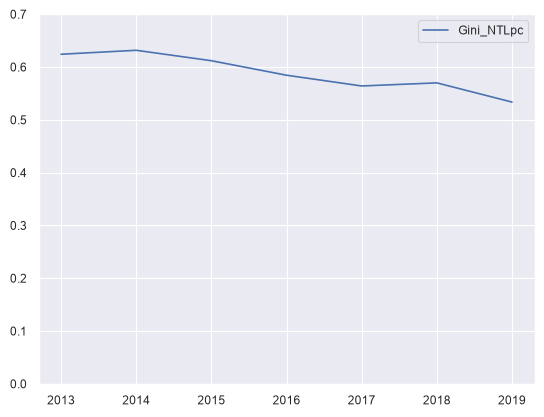

In [138]:
# Inequality is measured on levels: night-time lights per person (a Gini of logs is not an inequality index)
df_NTL_HDI["NTLpc"] = df_NTL_HDI["NTL"] / df_NTL_HDI["pop"]
dfWIDE_NTLpc = df_NTL_HDI.pivot_table(index=["GDLcode", "region"], columns="year", values="NTLpc").reset_index(drop=False)
dfWIDE_NTLpc.columns = dfWIDE_NTLpc.columns.astype(str)
gdf_NTLpc = pd.merge(polygonsFile, dfWIDE_NTLpc, on=["GDLcode", "region"], how="inner")
ax = gdf_NTLpc[years].apply(gini_by_col, axis=0).to_frame("Gini_NTLpc").plot()
ax.set_ylim(0, 0.70)
plt.show()

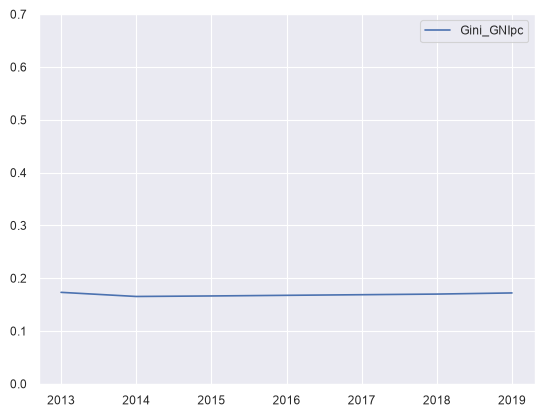

In [139]:
# GNI per capita in levels
dfWIDE_GNIpc = df_NTL_HDI.pivot_table(index=["GDLcode", "region"], columns="year", values="gnic").reset_index(drop=False)
dfWIDE_GNIpc.columns = dfWIDE_GNIpc.columns.astype(str)
gdf_GNIpc = pd.merge(polygonsFile, dfWIDE_GNIpc, on=["GDLcode", "region"], how="inner")
ax = gdf_GNIpc[years].apply(gini_by_col, axis=0).to_frame("Gini_GNIpc").plot()
ax.set_ylim(0, 0.70)
plt.show()